In [ ]:
from google.colab import files
uploaded=files.upload()

Saving air-quality-india.csv to air-quality-india.csv


In [ ]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ["PROPHET_DISABLE_STDOUT"] = "1"
os.environ["PROPHET_DISABLE_PROGRESS"] = "1"
import logging
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from prophet import Prophet

fn = "air-quality-india.csv"
df = pd.read_csv(fn)
df.columns = df.columns.str.strip()
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.set_index("Timestamp")

In [ ]:
if "PM2.5" not in df.columns:
    raise KeyError("PM2.5 column not found!")
df["PM2.5"] = df["PM2.5"].interpolate(method="time").fillna(method="bfill").fillna(method="ffill")
daily = df["PM2.5"].resample("D").mean()
daily = daily.interpolate().fillna(method="bfill").fillna(method="ffill")
# Split data into training and test sets
test_days = 30
train = daily[:-test_days]
test = daily[-test_days:]

In [ ]:
#ARIMA model
arima_model = ARIMA(train, order=(5,1,0))
arima_fit = arima_model.fit()
arima_forecast = arima_fit.forecast(steps=test_days)
#ETS model
try:
    ets_model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=7)
    ets_fit = ets_model.fit()
    ets_forecast = ets_fit.forecast(test_days)
except:
    ets_model = ExponentialSmoothing(train, trend="add", seasonal=None)
    ets_fit = ets_model.fit()
    ets_forecast = ets_fit.forecast(test_days)

In [ ]:
#Prophet model
prophet_df = pd.DataFrame({"ds": train.index, "y": train.values})
prophet_model = Prophet(daily_seasonality=True, yearly_seasonality=True)
prophet_model.fit(prophet_df)
future = prophet_model.make_future_dataframe(periods=test_days)
forecast_prophet = prophet_model.predict(future)
prophet_forecast = forecast_prophet.set_index("ds")["yhat"].reindex(test.index)
prophet_forecast = prophet_forecast.fillna(method="ffill").fillna(method="bfill")


RMSE Scores:
ARIMA   : 4.402462242675959
ETS     : 4.047465406427919
Prophet : 12.69243775593417


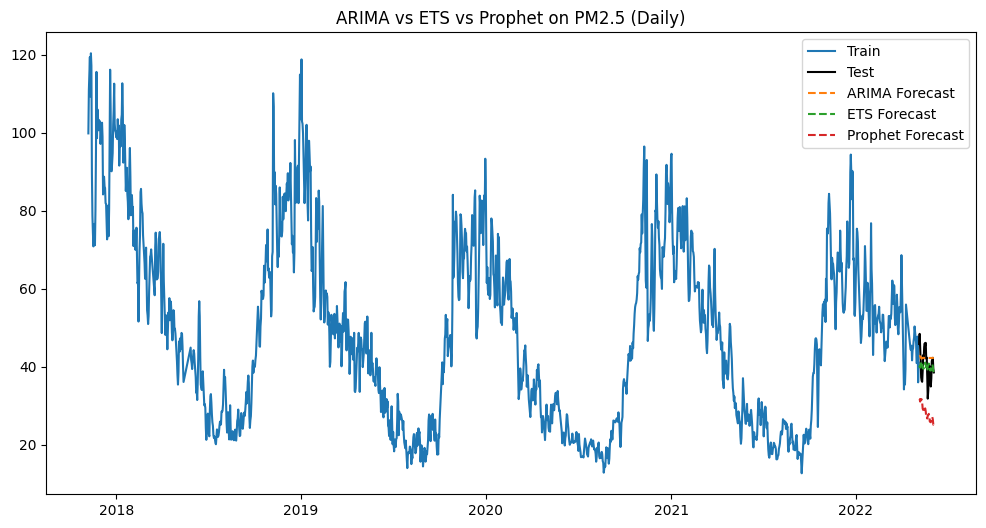

In [ ]:
#RMSE scores
rmse_arima = sqrt(mean_squared_error(test, arima_forecast))
rmse_ets = sqrt(mean_squared_error(test, ets_forecast))
rmse_prophet = sqrt(mean_squared_error(test, prophet_forecast))
print("\nRMSE Scores:")
print("ARIMA   :", rmse_arima)
print("ETS     :", rmse_ets)
print("Prophet :", rmse_prophet)
# Plot
plt.figure(figsize=(12,6))
plt.plot(train.index, train, label="Train")
plt.plot(test.index, test, label="Test", color="black")
plt.plot(test.index, arima_forecast, label="ARIMA Forecast", linestyle="--")
plt.plot(test.index, ets_forecast, label="ETS Forecast", linestyle="--")
plt.plot(test.index, prophet_forecast, label="Prophet Forecast", linestyle="--")
plt.legend()
plt.title("ARIMA vs ETS vs Prophet on PM2.5 (Daily)")
plt.show()

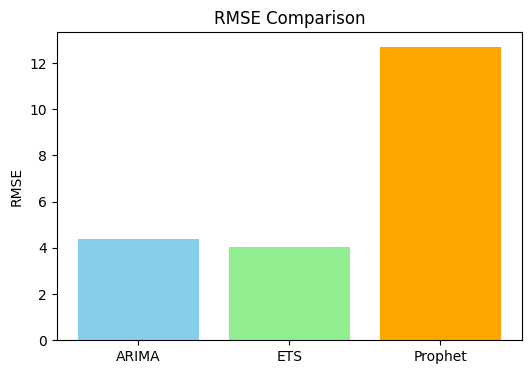

In [ ]:
rmse_values = [rmse_arima, rmse_ets, rmse_prophet]
models = ["ARIMA", "ETS", "Prophet"]
plt.figure(figsize=(6,4))
plt.bar(models, rmse_values, color=['skyblue','lightgreen','orange'])
plt.ylabel("RMSE")
plt.title("RMSE Comparison")
plt.show()

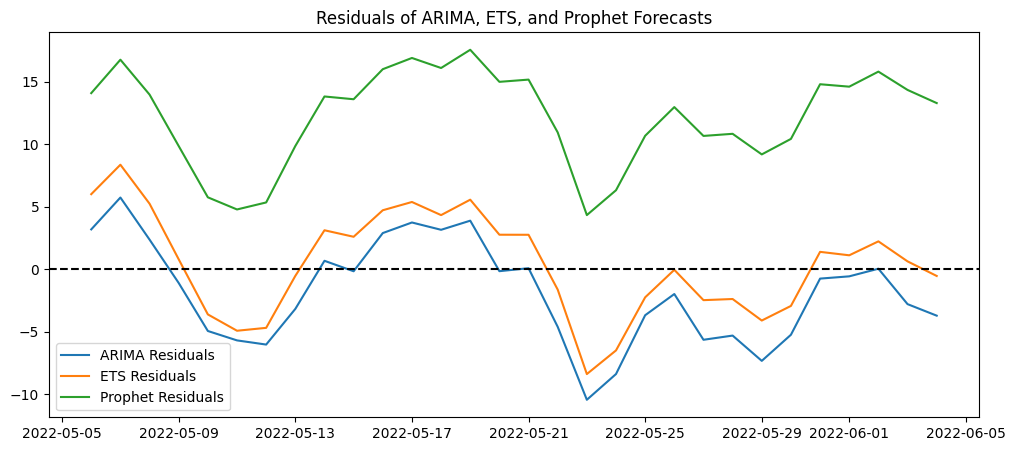

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(test.index, test - arima_forecast, label="ARIMA Residuals")
plt.plot(test.index, test - ets_forecast, label="ETS Residuals")
plt.plot(test.index, test - prophet_forecast, label="Prophet Residuals")
plt.axhline(0, color='black', linestyle='--')
plt.legend()
plt.title("Residuals of ARIMA, ETS, and Prophet Forecasts")
plt.show()